# Загрузка очищенных данных

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

df_clean = pd.read_parquet("data/clean.parquet")
print(f"Shape: {df_clean.shape}")

Shape: (1470, 34)


# Сегментация: Топы (Top Talent) vs Остальные (Core Staff)


In [2]:
pd.crosstab(df_clean["JobLevel"], df_clean["PerformanceRating"])

PerformanceRating,3,4
JobLevel,,
1,455,88
2,454,80
3,185,33
4,88,18
5,62,7


In [3]:
df_clean["is_top"] = ((df_clean["PerformanceRating"] == 4) | (df_clean["JobLevel"] >= 3)).astype(int)

top_df = df_clean[df_clean["is_top"] == 1].copy()
rest_df = df_clean[df_clean["is_top"] == 0].copy()

print(f"Всего сотрудников: {len(df_clean)} | Общий отток: {df_clean['is_attrition'].mean():.1%}")
print(f"Топы: {len(top_df)} чел. | Отток топов: {top_df['is_attrition'].mean():.1%}")
print(f"Остальные: {len(rest_df)} чел. | Отток остальных: {rest_df['is_attrition'].mean():.1%}")


Всего сотрудников: 1470 | Общий отток: 16.1%
Топы: 561 чел. | Отток топов: 13.4%
Остальные: 909 чел. | Отток остальных: 17.8%


# Корреляционный анализ Спирмена (сравнение драйверов Топов и Остальных)

In [4]:
num_cols = (
    df_clean.select_dtypes(include=[np.number])
    .columns.drop(["is_attrition", "is_top", "PerformanceRating", "EmployeeNumber"])
)

corr_comparison = pd.DataFrame({
    "Spearman_Top": top_df[num_cols].corrwith(top_df["is_attrition"], method="spearman"),
    "Spearman_Rest": rest_df[num_cols].corrwith(rest_df["is_attrition"], method="spearman")
})

corr_comparison["Top_Rest_Ratio"] = corr_comparison["Spearman_Top"] / corr_comparison["Spearman_Rest"]
corr_comparison.sort_values(by="Top_Rest_Ratio", ascending=False).round(3)

,Spearman_Top,Spearman_Rest,Top_Rest_Ratio
TrainingTimesLastYear,-0.123,-0.016,7.529
DistanceFromHome,0.138,0.047,2.914
HourlyRate,-0.012,-0.005,2.558
MonthlyRate,0.023,0.012,1.875
JobSatisfaction,-0.118,-0.096,1.229
EnvironmentSatisfaction,-0.103,-0.096,1.074
StockOptionLevel,-0.180,-0.168,1.073
JobInvolvement,-0.122,-0.120,1.016
MonthlyIncome,-0.196,-0.202,0.972
JobLevel,-0.181,-0.201,0.903


In [5]:
# Оценка Attrition Rate Lift по ключевым факторам

In [6]:
def calc_lift(data, col):
    base_rate = data["is_attrition"].mean()
    stats = data.groupby(col)["is_attrition"].agg(count="count", attrition_rate="mean")
    stats["lift"] = stats["attrition_rate"] / base_rate
    stats["attrition_rate"] = (stats["attrition_rate"] * 100).round(1)
    stats["lift"] = stats["lift"].round(2)
    return stats

In [7]:
calc_lift(top_df, "OverTime")

,count,attrition_rate,lift
OverTime,,,
No,395,8.9,0.66
Yes,166,24.1,1.80


In [8]:
calc_lift(rest_df, "OverTime")

,count,attrition_rate,lift
OverTime,,,
No,659,11.4,0.64
Yes,250,34.8,1.95


In [9]:
calc_lift(top_df, "StockOptionLevel")

,count,attrition_rate,lift
StockOptionLevel,,,
0,227,22.0,1.65
1,253,6.7,0.50
2,52,5.8,0.43
3,29,17.2,1.29


In [10]:
calc_lift(top_df, "TrainingTimesLastYear")

,count,attrition_rate,lift
TrainingTimesLastYear,,,
0,20,30.0,2.24
1,27,11.1,0.83
2,221,18.1,1.35
3,181,7.7,0.58
4,43,14.0,1.04
5,46,10.9,0.81
6,23,4.3,0.33


In [11]:
top_df["median_role_income"] = top_df.groupby(["JobRole", "JobLevel"])["MonthlyIncome"].transform("median")
top_df["is_below_median"] = (top_df["MonthlyIncome"] < top_df["median_role_income"]).astype(int)
calc_lift(top_df, "is_below_median")

,count,attrition_rate,lift
is_below_median,,,
0,288,12.5,0.94
1,273,14.3,1.07


In [12]:
top_df["far_from_home"] = (top_df["DistanceFromHome"] >= 15).astype(int)
calc_lift(top_df, "far_from_home")

,count,attrition_rate,lift
far_from_home,,,
0,422,11.4,0.85
1,139,19.4,1.45


# Визуализация распределений (KDE) для непрерывных признаков Топов

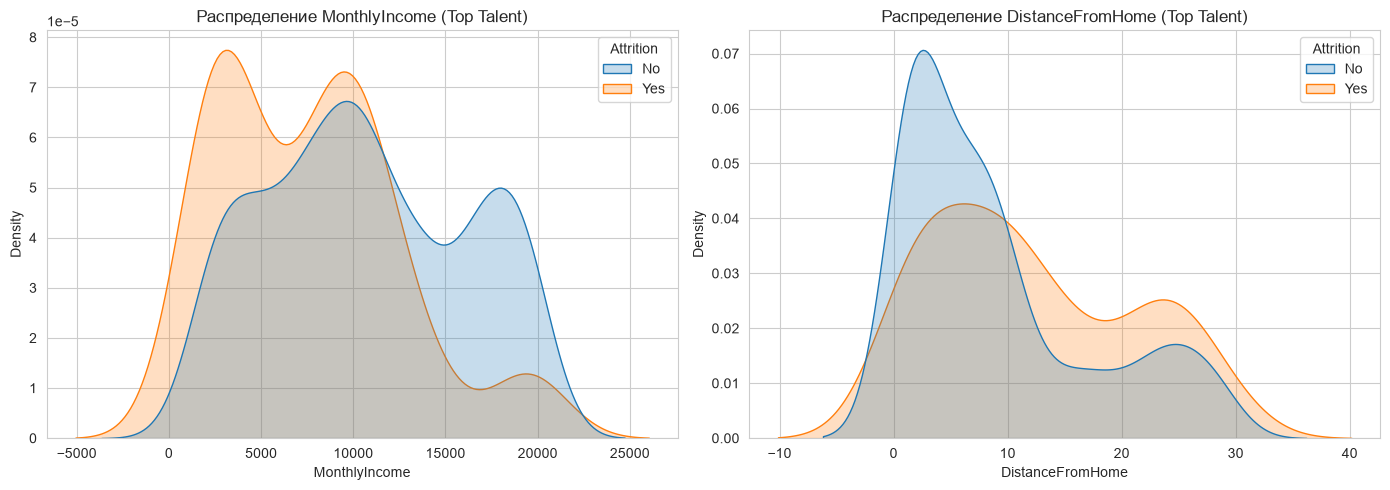

In [13]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

sns.kdeplot(data=top_df, x="MonthlyIncome", hue="Attrition", common_norm=False, fill=True, ax=ax1)
ax1.set_title("Распределение MonthlyIncome (Top Talent)")

sns.kdeplot(data=top_df, x="DistanceFromHome", hue="Attrition", common_norm=False, fill=True, ax=ax2)
ax2.set_title("Распределение DistanceFromHome (Top Talent)")

plt.tight_layout()
plt.show()

# Ключевые выводы EDA
* Отток среди Топов ниже среднего по компании (13.4% против 17.8%), однако мотивация этой группы существенно отличается от остального штата.
* Главные специфические драйверы удержания Топов: наличие опционов (StockOptionLevel), регулярное обучение (TrainingTimesLastYear >= 3, снижение оттока в 2-4 раза) и близость к офису (DistanceFromHome < 11).
* Отклонение зарплаты от медианы внутри грейда (is_below_median) не показало значимого влияния на отток (Lift 1.07) — критичным является абсолютный уровень дохода и отсутствие опционного пакета.
